In [20]:
import pandas as pd

df = pd.read_csv("Envoy_Air.csv")

print(df.shape)


(1072778, 61)


Valeurs manquantes

In [21]:
manquantes = df.isnull().sum()

resultat = pd.DataFrame({
    "Valeurs manquantes": manquantes,
    "Pourcentage (%)": (manquantes / len(df) * 100).round(2)
})

display(
    resultat[resultat["Valeurs manquantes"] > 0]
    .sort_values("Pourcentage (%)", ascending=False)
)

,Valeurs manquantes,Pourcentage (%)
ArrivalDelayGroups,38799,3.62
ArrDel15,38799,3.62
ArrDelayMinutes,38799,3.62
AirTime,38799,3.62
ActualElapsedTime,38799,3.62
ArrDelay,38799,3.62
ArrTime,36389,3.39
TaxiIn,36389,3.39
WheelsOn,36389,3.39
WheelsOff,35857,3.34


Suppression des valeurs manquantes dans les variables cibles

In [22]:
# Afficher les NaN avant la suppression
print("NaN dans ArrDel15 :", df["ArrDel15"].isna().sum())
print("NaN dans ArrDelayMinutes :", df["ArrDelayMinutes"].isna().sum())

# Nombre de lignes avant
lignes_avant = len(df)

# Supprimer les lignes où au moins une cible est NaN
df = df.dropna(subset=["ArrDel15", "ArrDelayMinutes"])

# Résultat
print("Lignes supprimées :", lignes_avant - len(df))
print("Lignes restantes :", len(df))

NaN dans ArrDel15 : 38799
NaN dans ArrDelayMinutes : 38799
Lignes supprimées : 38799
Lignes restantes : 1033979


Vérification des doublons

In [23]:
colonnes_dupliquees = []

for i in range(len(df.columns)):
    for j in range(i + 1, len(df.columns)):
        if df.iloc[:, i].equals(df.iloc[:, j]):
            colonnes_dupliquees.append(
                (df.columns[i], df.columns[j])
            )

print("Colonnes dupliquées :", colonnes_dupliquees)

Colonnes dupliquées : [('Cancelled', 'Diverted'), ('Marketing_Airline_Network', 'IATA_Code_Marketing_Airline'), ('Flight_Number_Marketing_Airline', 'Flight_Number_Operating_Airline'), ('Operating_Airline', 'IATA_Code_Operating_Airline')]


Supression des variables duppliquées.

In [24]:
# Supprimer la deuxième variable de chaque couple
colonnes_a_supprimer = list(dict.fromkeys(
    col2 for col1, col2 in colonnes_dupliquees
))

df = df.drop(columns=colonnes_a_supprimer)

# Afficher les résultats
print("Variables supprimées :", colonnes_a_supprimer)
print("Nombre de variables supprimées :", len(colonnes_a_supprimer))
print("Nombre de variables restantes :", len(df.columns))

Variables supprimées : ['Diverted', 'IATA_Code_Marketing_Airline', 'Flight_Number_Operating_Airline', 'IATA_Code_Operating_Airline']
Nombre de variables supprimées : 4
Nombre de variables restantes : 57


Variables fortement corrélés

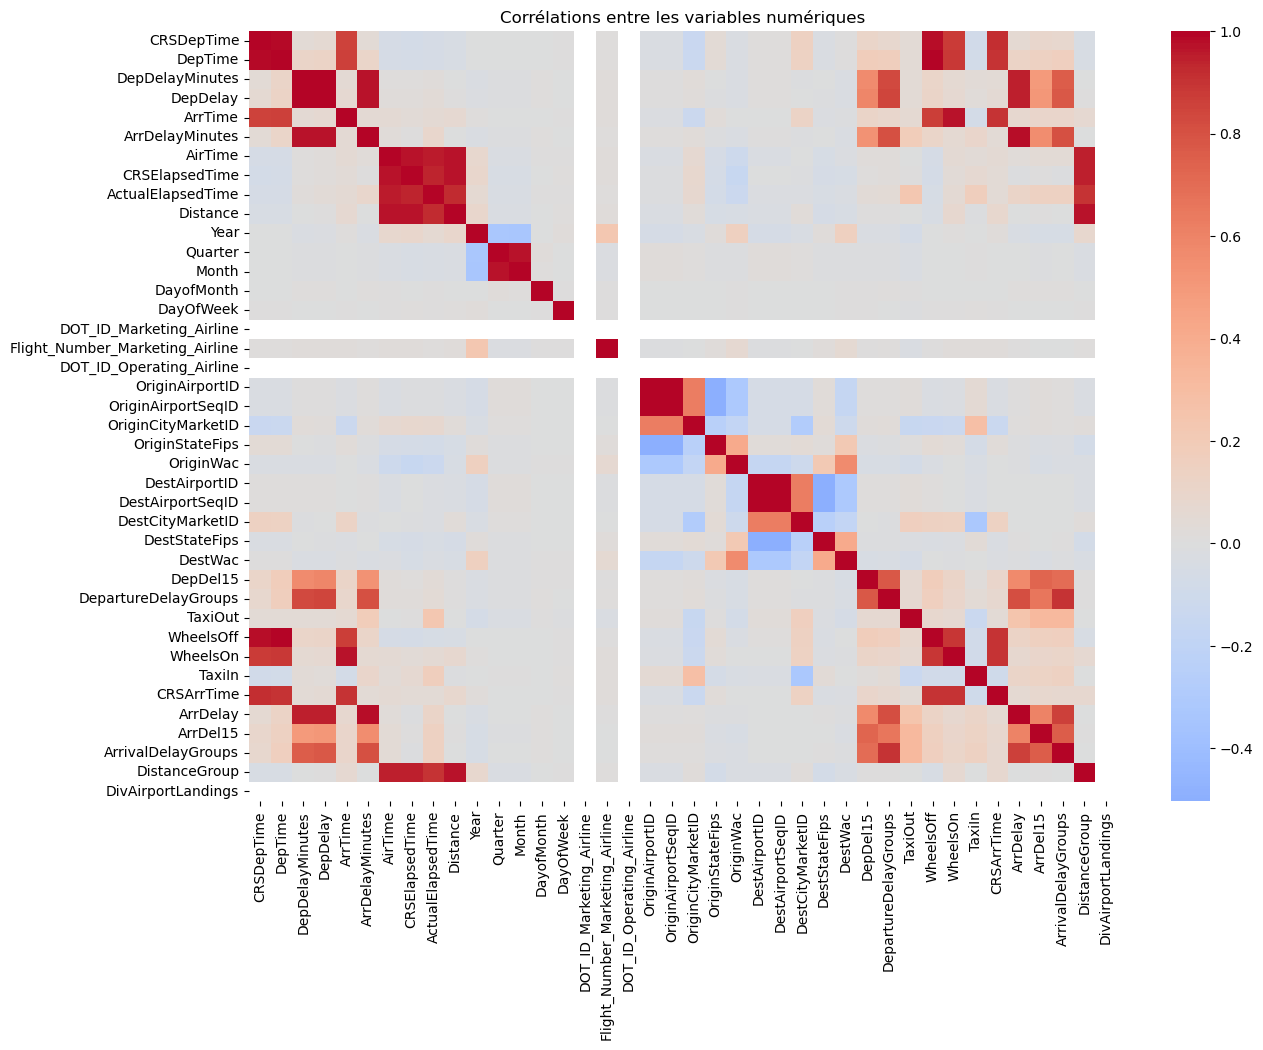

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

correlations = df.select_dtypes(include="number").corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlations, cmap="coolwarm", center=0)
plt.title("Corrélations entre les variables numériques")
plt.show()

Suppression des variables fortement corréles

In [26]:
import pandas as pd

variables_a_garder = ["Distance", "ArrDelayMinutes", "ArrDel15", "Month"]
correlations = df.select_dtypes(include="number").corr().abs()
colonnes = correlations.columns

colonnes_a_supprimer = set()
correspondances = []

for i in range(len(colonnes)):
    for j in range(i + 1, len(colonnes)):
        col1 = colonnes[i]
        col2 = colonnes[j]
        correlation = correlations.loc[col1, col2]

        if correlation >= 0.95:
            if col1 in colonnes_a_supprimer or col2 in colonnes_a_supprimer:
                continue

            if col1 in variables_a_garder:
                supprimee, conservee = col2, col1
            elif col2 in variables_a_garder:
                supprimee, conservee = col1, col2
            else:
                supprimee, conservee = col2, col1

            if supprimee not in variables_a_garder:
                colonnes_a_supprimer.add(supprimee)
                correspondances.append({
                    "Variable supprimée": supprimee,
                    "Variable conservée (représentante)": conservee,
                    "Corrélation": round(correlation, 4)
                })

# Afficher un seul tableau
tableau_correlations = pd.DataFrame(correspondances)
display(tableau_correlations)

# Supprimer les variables du dataframe
df = df.drop(columns=list(colonnes_a_supprimer))

print("Nombre de variables supprimées :", len(colonnes_a_supprimer))
print("Nombre de variables restantes :", len(df.columns))

,Variable supprimée,Variable conservée (représentante),Corrélation
0,DepTime,CRSDepTime,0.9849
1,WheelsOff,CRSDepTime,0.9793
2,DepDelay,DepDelayMinutes,0.9962
3,DepDelayMinutes,ArrDelayMinutes,0.9714
4,WheelsOn,ArrTime,0.9743
5,ArrDelay,ArrDelayMinutes,0.9800
6,CRSElapsedTime,AirTime,0.9735
7,ActualElapsedTime,AirTime,0.9570
8,AirTime,Distance,0.9710
9,DistanceGroup,Distance,0.9744


Nombre de variables supprimées : 13
Nombre de variables restantes : 44


Variables avec une seule valeur ou presque

In [31]:
for col in df.columns:
    frequences = df[col].value_counts(normalize=True, dropna=False)

    if len(frequences) <= 1:
        print(f"{col} : une seule valeur")
    elif frequences.iloc[0] >= 0.99:
        print(f"{col} : 99 % ou plus pour une même valeur")

Airline : une seule valeur
Cancelled : une seule valeur
Marketing_Airline_Network : une seule valeur
Operated_or_Branded_Code_Share_Partners : une seule valeur
DOT_ID_Marketing_Airline : une seule valeur
Operating_Airline : une seule valeur
DOT_ID_Operating_Airline : une seule valeur
DivAirportLandings : une seule valeur


Suppression des variables avec une seule valeur.

In [32]:
# Identifier les colonnes à supprimer
colonnes_a_supprimer = []

for col in df.columns:
    frequences = df[col].value_counts(normalize=True, dropna=False)

    if len(frequences) <= 1 or frequences.iloc[0] >= 0.99:
        colonnes_a_supprimer.append(col)

# Supprimer les colonnes
df = df.drop(columns=colonnes_a_supprimer)

# Afficher les résultats
print("Colonnes supprimées :")
for col in colonnes_a_supprimer:
    print("-", col)

print("\nNombre de colonnes supprimées :", len(colonnes_a_supprimer))
print("Nombre de colonnes restantes :", len(df.columns))

Colonnes supprimées :
- Airline
- Cancelled
- Marketing_Airline_Network
- Operated_or_Branded_Code_Share_Partners
- DOT_ID_Marketing_Airline
- Operating_Airline
- DOT_ID_Operating_Airline
- DivAirportLandings

Nombre de colonnes supprimées : 8
Nombre de colonnes restantes : 36


Distribution des retards

Vérifier les catégories des variables importantes